# Quality Analysis

## Calculating Density

In [2]:
import json
import csv
from pathlib import Path


INPUT_FILE = Path("../results/analysis_results.jsonl")
OUTPUT_FILE = Path("../results/analysis_results_density.csv")


GENERATION_LABELS = {
    0: "no-llm",
    1: "llm-era",
    2: "agentic",
}

# Metrics that are already densities and should be preserved as-is.
DENSITY_METRICS = {
    "duplicated_lines_density",
    "comment_lines_density",
}

# Metrics for which dividing by the number of functions is not meaningful.
NON_DENSITY_METRICS = {
    "reliability_rating",
    "security_rating",
    "sqale_rating",
}


def calculate_density(value, functions):
    if value is None or functions is None or functions == 0:
        return None

    return value / functions


rows = []

with INPUT_FILE.open("r", encoding="utf-8") as file:
    for line in file:
        line = line.strip()

        if not line:
            continue

        project = json.loads(line)

        project_id = project["project_id"]

        sonar_data = (
            project["tools"]
            ["sonarqube"]
            ["data"]
        )

        # Determine the language from SonarQube.
        languages = sonar_data.get("languages", [])

        if "java" in languages:
            language = "java"
        elif "py" in languages:
            language = "python"
        else:
            language = "unknown"

        versions = sonar_data["versions"]

        for version_index, (version_id, version_data) in enumerate(versions.items()):
            metrics = version_data["metrics"]

            if version_index not in GENERATION_LABELS:
                raise ValueError(
                    f"Unexpected version index {version_index} "
                    f"for project {project_id}"
                )

            row = {
                "project_id": project_id,
                "language": language,
                "version": version_id,
                "version_order": version_index + 1,
                "generation": GENERATION_LABELS[version_index],
            }

            functions = metrics.get("functions")

            for metric, value in metrics.items():
                if metric == "functions":
                    continue

                if metric in DENSITY_METRICS:
                    row[metric] = value

                elif metric in NON_DENSITY_METRICS:
                    row[metric] = value

                else:
                    row[f"density_{metric}"] = calculate_density(
                        value,
                        functions,
                    )

            rows.append(row)


# Collect all columns so every row has the same structure.
columns = [
    "project_id",
    "language",
    "version",
    "version_order",
    "generation",
]

metric_columns = sorted(
    {
        key
        for row in rows
        for key in row
        if key not in columns
    }
)

columns.extend(metric_columns)


with OUTPUT_FILE.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=columns)
    writer.writeheader()
    writer.writerows(rows)


print(f"Created {OUTPUT_FILE}")
print(f"Rows: {len(rows)}")
print(f"Java projects: {sum(row['language'] == 'java' for row in rows)}")
print(f"Python projects: {sum(row['language'] == 'python' for row in rows)}")
print(f"Unknown projects: {sum(row['language'] == 'unknown' for row in rows)}")

Created ..\results\analysis_results_density.csv
Rows: 150
Java projects: 72
Python projects: 78
Unknown projects: 0


## Data check

In [3]:
import pandas as pd

df = pd.read_csv("../results/analysis_results_density.csv")

print("=" * 80)
print("DATASET OVERVIEW")
print("=" * 80)
print(f"Rows:     {len(df):,}")
print(f"Projects: {df['project_id'].nunique():,}")
print(f"Columns:  {len(df.columns):,}")

print("\n" + "=" * 80)
print("ROWS BY GENERATION")
print("=" * 80)
print(df["generation"].value_counts().sort_index())

print("\n" + "=" * 80)
print("ROWS BY LANGUAGE")
print("=" * 80)
print(df["language"].value_counts())

print("\n" + "=" * 80)
print("PROJECTS BY LANGUAGE")
print("=" * 80)
print(df.groupby("language")["project_id"].nunique())

print("\n" + "=" * 80)
print("PROJECTS BY GENERATION")
print("=" * 80)
print(df.groupby("generation")["project_id"].nunique())

print("\n" + "=" * 80)
print("PROJECTS × GENERATION")
print("=" * 80)
print(
    df.groupby(["generation", "language"])["project_id"]
      .nunique()
      .unstack(fill_value=0)
)

print("\n" + "=" * 80)
print("MISSING VALUES")
print("=" * 80)

missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) == 0:
    print("No missing values.")
else:
    print(missing)

print("\n" + "=" * 80)
print("DUPLICATE PROJECT / GENERATION ROWS")
print("=" * 80)

duplicates = df.duplicated(
    subset=["project_id", "generation"],
    keep=False
)

print(f"Duplicate rows: {duplicates.sum():,}")

print("\n" + "=" * 80)
print("NUMERIC METRICS")
print("=" * 80)

numeric_columns = df.select_dtypes(include="number").columns

stats = df[numeric_columns].describe().T
stats["missing"] = df[numeric_columns].isna().sum()
stats["missing_%"] = (
    df[numeric_columns].isna().mean() * 100
)

print(
    stats[
        [
            "count",
            "missing",
            "missing_%",
            "mean",
            "std",
            "min",
            "25%",
            "50%",
            "75%",
            "max",
        ]
    ].round(4).to_string()
)

print("\n" + "=" * 80)
print("MEDIAN METRICS BY GENERATION")
print("=" * 80)

print(
    df.groupby("generation")[numeric_columns]
      .median()
      .T
      .round(4)
      .to_string()
)

print("\n" + "=" * 80)
print("MEAN METRICS BY GENERATION")
print("=" * 80)

print(
    df.groupby("generation")[numeric_columns]
      .mean()
      .T
      .round(4)
      .to_string()
)

DATASET OVERVIEW
Rows:     150
Projects: 50
Columns:  21

ROWS BY GENERATION
generation
agentic    50
llm-era    50
no-llm     50
Name: count, dtype: int64

ROWS BY LANGUAGE
language
python    78
java      72
Name: count, dtype: int64

PROJECTS BY LANGUAGE
language
java      24
python    26
Name: project_id, dtype: int64

PROJECTS BY GENERATION
generation
agentic    50
llm-era    50
no-llm     50
Name: project_id, dtype: int64

PROJECTS × GENERATION
language    java  python
generation              
agentic       24      26
llm-era       24      26
no-llm        24      26

MISSING VALUES
No missing values.

DUPLICATE PROJECT / GENERATION ROWS
Duplicate rows: 0

NUMERIC METRICS
                              count  missing  missing_%     mean      std     min      25%      50%      75%       max
version_order                 150.0        0        0.0   2.0000   0.8192  1.0000   1.0000   2.0000   3.0000    3.0000
comment_lines_density         150.0        0        0.0  15.5447  10.2764  1

## Ploting

In [17]:
categories = {
    # "Code Size": [
    #     "density_ncloc",
    #     "density_statements",
    # ],

    "Complexity": [
        "density_complexity",
        "density_cognitive_complexity",
    ],

    "Maintainability": [
        "density_code_smells",
        "duplicated_lines_density",
        "density_sqale_index",
        "comment_lines_density",
    ],

    "Reliability": [
        "density_bugs",
    ],

    "Security": [
        "density_vulnerabilities",
        "density_security_hotspots",
    ],
}



metric_labels = {
    # "density_ncloc": "NCLOC",
    # "density_statements": "Statements",

    "density_complexity": "Cyclomatic",
    "density_cognitive_complexity": "Cognitive",

    "density_code_smells": "Smells",
    "duplicated_lines_density": "DLD",
    "density_sqale_index": "SQALE",
    "comment_lines_density": "CLD",

    "density_bugs": "Bugs",

    "density_vulnerabilities": "Vulnerabilities",
    "density_security_hotspots": "Sec. Hotspots",
}

### Overall

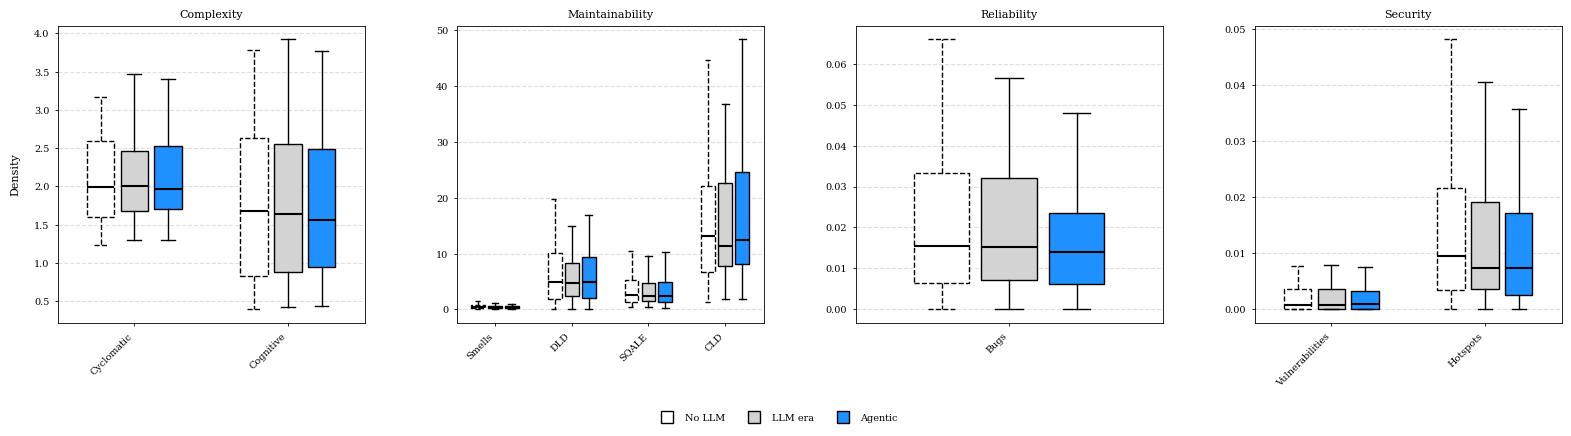

Saved: ..\analysis\density_plots\density_boxplot.pdf


In [5]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path


INPUT_FILE = "../results/analysis_results_density.csv"
OUTPUT_DIR = Path("../analysis/density_plots")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(INPUT_FILE)


generation_order = [
    "no-llm",
    "llm-era",
    "agentic",
]

generation_labels = {
    "no-llm": "No LLM",
    "llm-era": "LLM era",
    "agentic": "Agentic",
}


generation_colors = {
    "no-llm": "white",
    "llm-era": "lightgray",
    "agentic": "dodgerblue",
}


generation_offsets = {
    "no-llm": -0.22,
    "llm-era": 0.00,
    "agentic": 0.22,
}


box_width = 0.18


fig, axes = plt.subplots(
    1,
    4,
    figsize=(16, 4.5)
)

axes = axes.flatten()


for ax, (category, metrics) in zip(
    axes,
    categories.items()
):

    available_metrics = [
        metric
        for metric in metrics
        if metric in df.columns
    ]

    positions = range(
        1,
        len(available_metrics) + 1
    )

    for i, metric in enumerate(available_metrics):

        for generation in generation_order:

            values = (
                df.loc[
                    df["generation"] == generation,
                    metric
                ]
                .dropna()
            )

            if values.empty:
                continue

            position = (
                i
                + 1
                + generation_offsets[generation]
            )

            bp = ax.boxplot(
                [values],
                positions=[position],
                widths=box_width,
                patch_artist=True,
                showfliers=False
            )

            for patch in bp["boxes"]:

                patch.set_facecolor(
                    generation_colors[generation]
                )

                patch.set_edgecolor("black")

                if generation == "no-llm":
                    patch.set_linestyle("--")

            for whisker in bp["whiskers"]:

                whisker.set_color("black")

                if generation == "no-llm":
                    whisker.set_linestyle("--")

            for cap in bp["caps"]:

                cap.set_color("black")

                if generation == "no-llm":
                    cap.set_linestyle("--")

            for median in bp["medians"]:

                median.set_color("black")
                median.set_linewidth(1.5)

    ax.set_xticks(
        list(positions)
    )

    ax.set_xticklabels(
        [
            metric_labels[metric]
            for metric in available_metrics
        ],
        rotation=45,
        ha="right"
    )

    ax.set_title(category)

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.4
    )

    ax.set_xlim(
        0.5,
        len(available_metrics) + 0.5
    )


# Density label only on the first panel

axes[0].set_ylabel(
    "Density",
    rotation=90,
    labelpad=10
)


legend_handles = []

for generation in generation_order:

    handle = plt.Line2D(
        [0],
        [0],
        color="black",
        marker="s",
        markersize=9,
        markerfacecolor=generation_colors[generation],
        markeredgecolor="black",
        linestyle="None",
        label=generation_labels[generation]
    )

    legend_handles.append(handle)


fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=3,
    frameon=False
)


plt.subplots_adjust(
    left=0.05,
    right=0.99,
    bottom=0.22,
    top=0.88,
    wspace=0.30
)


output_file = (
    OUTPUT_DIR
    / "density_boxplot.pdf"
)

plt.savefig(
    output_file,
    format="pdf",
    bbox_inches="tight"
)

plt.show()
plt.close()

print(f"Saved: {output_file}")

In [6]:
import pandas as pd
from pathlib import Path


INPUT_FILE = "../results/analysis_results_density.csv"
OUTPUT_DIR = Path("../analysis/density_plots")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(INPUT_FILE)
metrics = {
    "density_complexity": "Cyclomatic Complexity",
    "density_cognitive_complexity": "Cognitive Complexity",

    "density_code_smells": "Code Smells",
    "duplicated_lines_density": "Duplicated Lines",
    "density_sqale_index": "SQALE Index",
    "comment_lines_density": "CLD",

    "density_bugs": "Bugs",

    "density_vulnerabilities": "Vulnerabilities",
    "density_security_hotspots": "Security Hotspots",
}
generation_order = [
    "no-llm",
    "llm-era",
    "agentic",
]


generation_labels = {
    "no-llm": "No LLM",
    "llm-era": "LLM era",
    "agentic": "Agentic",
}


def calculate_statistics(data, scope):

    rows = []

    for generation in generation_order:

        generation_data = data[
            data["generation"] == generation
        ]

        for metric, metric_label in metrics.items():

            if metric not in generation_data.columns:
                continue

            values = generation_data[metric].dropna()

            if values.empty:
                continue

            rows.append({
                "Scope": scope,
                "Generation": generation_labels[generation],
                "Metric": metric_label,
                "N": len(values),
                "Mean": values.mean(),
                "Median": values.median(),
                "Min": values.min(),
                "Q1": values.quantile(0.25),
                "Q3": values.quantile(0.75),
                "Max": values.max(),
            })

    return pd.DataFrame(rows)


# Overall: Java + Python pooled

overall = calculate_statistics(
    df,
    "Overall"
)


# Per language

languages = sorted(
    df["language"].dropna().unique()
)

language_tables = []

for language in languages:

    language_data = df[
        df["language"] == language
    ]

    language_table = calculate_statistics(
        language_data,
        language
    )

    language_tables.append(
        language_table
    )


# Combine everything

results = pd.concat(
    [overall] + language_tables,
    ignore_index=True
)


# Round numeric columns

numeric_columns = [
    "Mean",
    "Median",
    "Min",
    "Q1",
    "Q3",
    "Max",
]

results[numeric_columns] = results[
    numeric_columns
].round(6)


# Save combined table

output_file = (
    OUTPUT_DIR
    / "density_boxplot_statistics.csv"
)

results.to_csv(
    output_file,
    index=False
)


# Print overall table

print("\n" + "=" * 100)
print("OVERALL — JAVA + PYTHON")
print("=" * 100)

print(
    overall.to_string(
        index=False
    )
)


# Print per-language tables

for language, table in zip(
    languages,
    language_tables
):

    print("\n" + "=" * 100)
    print(language.upper())
    print("=" * 100)

    print(
        table.to_string(
            index=False
        )
    )


print("\nSaved:")
print(output_file)


OVERALL — JAVA + PYTHON
  Scope Generation                Metric  N      Mean    Median      Min       Q1        Q3        Max
Overall     No LLM Cyclomatic Complexity 50  2.215724  1.997381 1.235527 1.601473  2.593667   5.923077
Overall     No LLM  Cognitive Complexity 50  2.059447  1.675784 0.394904 0.825219  2.628822  11.072527
Overall     No LLM           Code Smells 50  0.604003  0.349406 0.056868 0.207228  0.793748   2.821656
Overall     No LLM      Duplicated Lines 50  7.132000  4.950000 0.000000 1.775000 10.150000  42.200000
Overall     No LLM           SQALE Index 50  3.962449  2.555432 0.378343 1.330312  5.232103  14.799232
Overall     No LLM                   CLD 50 15.482000 13.150000 1.300000 6.775000 22.150000  44.700000
Overall     No LLM                  Bugs 50  0.035810  0.015432 0.000000 0.006501  0.033248   0.781130
Overall     No LLM       Vulnerabilities 50  0.006271  0.000800 0.000000 0.000000  0.003675   0.088915
Overall     No LLM     Security Hotspots 50  0.0

### Per language

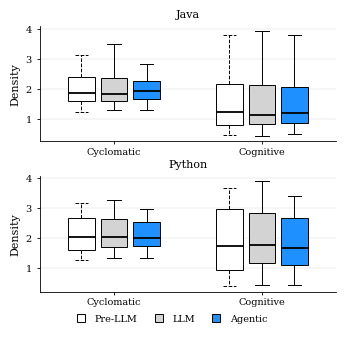

Saved: ..\analysis\density_plots_per_lang\complexity_boxplot.pdf


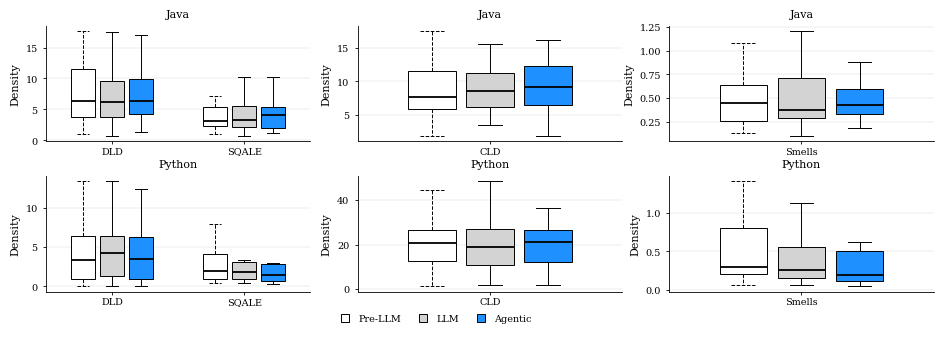

Saved: ..\analysis\density_plots_per_lang\maintainability_boxplot.pdf


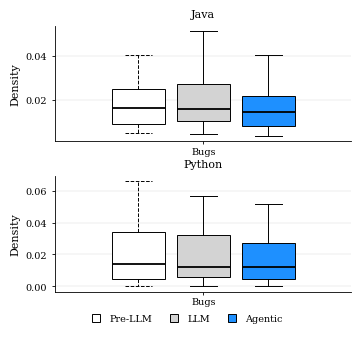

Saved: ..\analysis\density_plots_per_lang\reliability_boxplot.pdf


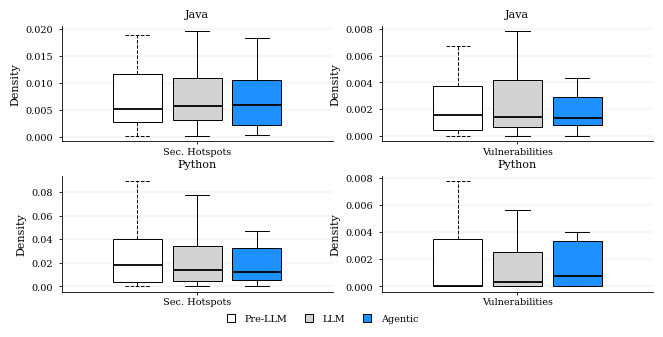

Saved: ..\analysis\density_plots_per_lang\security_boxplot.pdf
       Category Language Generation          Metric  N      Mean    Median      Min        Q1        Q3        Max
     Complexity     Java    Pre-LLM      Cyclomatic 24  2.080645  1.841128 1.235527  1.588600  2.389533   4.647285
     Complexity     Java        LLM      Cyclomatic 24  2.094390  1.821638 1.296226  1.582092  2.362581   4.477513
     Complexity     Java    Agentic      Cyclomatic 24  2.140223  1.929520 1.301045  1.650025  2.256404   4.871452
     Complexity     Java    Pre-LLM       Cognitive 24  1.676294  1.237191 0.450158  0.774622  2.165723   5.938563
     Complexity     Java        LLM       Cognitive 24  1.682307  1.126254 0.422762  0.817921  2.114087   6.351343
     Complexity     Java    Agentic       Cognitive 24  1.687280  1.199651 0.484470  0.846319  2.055978   6.517529
     Complexity   Python    Pre-LLM      Cyclomatic 26  2.340412  2.019762 1.267516  1.617094  2.649162   5.923077
     Complexity  

In [20]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5, "pdf.fonttype": 42, "ps.fonttype": 42})

INPUT_FILE = "../results/analysis_results_density.csv"
OUTPUT_DIR = Path("../analysis/density_plots_per_lang")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(INPUT_FILE)

generation_order = ["no-llm", "llm-era", "agentic"]
generation_labels = {"no-llm": "Pre-LLM", "llm-era": "LLM", "agentic": "Agentic"}
generation_colors = {"no-llm": "white", "llm-era": "lightgray", "agentic": "dodgerblue"}
offsets = {"no-llm": -0.22, "llm-era": 0.00, "agentic": 0.22}
box_width = 0.18
cld_metric = "comment_lines_density"
statistics = []

def draw(ax, values_list, positions, generation, color):
    if not values_list:
        return
    ls = "--" if generation == "no-llm" else "-"
    bp = ax.boxplot(values_list, positions=positions, widths=box_width, patch_artist=True, showfliers=False,
                    boxprops=dict(facecolor=color, edgecolor="black", linestyle=ls, linewidth=0.7),
                    whiskerprops=dict(color="black", linestyle=ls, linewidth=0.7),
                    capprops=dict(color="black", linestyle=ls, linewidth=0.7),
                    medianprops=dict(color="black", linewidth=1.3))
    for box in bp["boxes"]:
        box.set_facecolor(color)

def plot_category(category, metrics, separate_metrics=None):
    metrics = [m for m in metrics if m in df.columns]
    separate_metrics = separate_metrics or []
    separate_metrics = [m for m in separate_metrics if m in metrics]
    main_metrics = [m for m in metrics if m not in separate_metrics]
    plot_groups = [("main", main_metrics)] if main_metrics else []
    plot_groups.extend((metric, [metric]) for metric in separate_metrics)

    fig, axes = plt.subplots(2, len(plot_groups), figsize=(3.4 * len(plot_groups), 1.75 * 2), squeeze=False)

    for col, (group, group_metrics) in enumerate(plot_groups):
        for row, language in enumerate(["java", "python"]):
            ax = axes[row, col]
            lang_df = df[df["language"].str.lower() == language]
            available_metrics = [m for m in group_metrics if m in lang_df.columns]

            if not available_metrics:
                ax.axis("off")
                continue

            for i, metric in enumerate(available_metrics):
                for generation in generation_order:
                    values = lang_df.loc[lang_df["generation"] == generation, metric].dropna()
                    if values.empty:
                        continue

                    statistics.append({"Category": category, "Language": language.capitalize(),
                                       "Generation": generation_labels[generation],
                                       "Metric": metric_labels.get(metric, metric), "N": len(values),
                                       "Mean": values.mean(), "Median": values.median(), "Min": values.min(),
                                       "Q1": values.quantile(0.25), "Q3": values.quantile(0.75), "Max": values.max()})

                    draw(ax, [values], [i + 1 + offsets[generation]], generation, generation_colors[generation])

            ax.set_xticks(range(1, len(available_metrics) + 1))
            ax.set_xticklabels([metric_labels.get(m, m) for m in available_metrics])
            ax.set_xlim(0.5, len(available_metrics) + 0.5)
            ax.grid(axis="y", linewidth=0.3, alpha=0.5)
            ax.set_axisbelow(True)
            ax.spines[["top", "right"]].set_visible(False)
            ax.tick_params(axis="x", pad=1.5)
            ax.set_title(language.capitalize())
            ax.set_ylabel("Density")

    handles = [plt.Line2D([0], [0], color="black", marker="s", markersize=6,
                          markerfacecolor=generation_colors[g], markeredgecolor="black",
                          markeredgewidth=0.7, linestyle="None", label=generation_labels[g])
               for g in generation_order]

    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.005),
           ncol=3, frameon=False, columnspacing=1.2, handletextpad=0.4)
    fig.subplots_adjust(wspace=0.18, hspace=0.3, left=0.12, right=0.99, bottom=0.12, top=0.88)

    
    output_file = OUTPUT_DIR / f"{category.lower().replace(' ', '_')}_boxplot.pdf"
    plt.savefig(output_file, format="pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved: {output_file}")


for category, category_metrics in categories.items():
    separate_metrics = []

    if category.lower() == "maintainability":
        separate_metrics.append("comment_lines_density")

    if "density_code_smells" in category_metrics:
        separate_metrics.append("density_code_smells")

    if "density_vulnerabilities" in category_metrics:
        separate_metrics.append("density_vulnerabilities")

    plot_category(category, category_metrics, separate_metrics)

statistics_df = pd.DataFrame(statistics)
numeric_columns = ["Mean", "Median", "Min", "Q1", "Q3", "Max"]
statistics_df[numeric_columns] = statistics_df[numeric_columns].round(6)
statistics_file = OUTPUT_DIR / "density_boxplot_statistics.csv"
statistics_df.to_csv(statistics_file, index=False)
print(statistics_df.to_string(index=False))
print(f"\nSaved: {statistics_file}")

## Statistical testing

In [8]:
import argparse
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import norm, wilcoxon
from statsmodels.stats.multitest import multipletests

GENERATIONS = ["no-llm", "llm-era", "agentic"]
LANGUAGES = ["python", "java"]
DENSITY_METRICS = [
    "comment_lines_density",
    "density_bugs",
    "density_code_smells",
    "density_cognitive_complexity",
    "density_complexity",
    "density_security_hotspots",
    "density_sqale_index",
    "density_vulnerabilities",
    "duplicated_lines_density",
]

G = "C(generation, Treatment(reference='no-llm'))"
L = "C(language, Treatment(reference='python'))"
g2, g3 = f"{G}[T.llm-era]", f"{G}[T.agentic]"
i2, i3 = f"{g2}:{L}[T.java]", f"{g3}:{L}[T.java]"

CONTRASTS = {
    "V1-V2": {g2: 1},
    "V2-V3": {g3: 1, g2: -1},
    "V1-V3": {g3: 1},
}

INTERACTIONS = {
    "V1-V2": {i2: 1},
    "V2-V3": {i3: 1, i2: -1},
    "V1-V3": {i3: 1},
}

PAIRS = [
    ("no-llm", "llm-era", "V1-V2"),
    ("llm-era", "agentic", "V2-V3"),
    ("no-llm", "agentic", "V1-V3"),
]


def fit_model(data, metric):
    d = data[["project_id", "language", "generation", metric]].dropna().copy()
    d["y"] = np.log1p(d[metric].clip(lower=0))
    d["generation"] = pd.Categorical(
        d["generation"], categories=GENERATIONS, ordered=True
    )
    d["language"] = pd.Categorical(
        d["language"], categories=LANGUAGES
    )

    fit = smf.mixedlm(
        f"y ~ {G} * {L}",
        d,
        groups=d["project_id"]
    ).fit(
        reml=False,
        method="lbfgs",
        maxiter=2000,
        disp=False
    )

    return fit, d


def linear_contrast(fit, terms):
    names = list(fit.params.index)
    missing = [t for t in terms if t not in names]

    if missing:
        raise KeyError(
            f"Terms {missing} not found in model parameters:\n{names}"
        )

    c = pd.Series(terms, dtype=float).reindex(
        names, fill_value=0.0
    ).values

    est = float(c @ fit.params.values)

    se = float(
        np.sqrt(
            max(
                c
                @ fit.cov_params().loc[names, names].values
                @ c,
                0
            )
        )
    )

    z = est / se if se > 0 else np.nan
    p = 2 * norm.sf(abs(z)) if np.isfinite(z) else np.nan

    pct = lambda x: (np.exp(x) - 1) * 100

    return {
        "estimate_log": est,
        "se": se,
        "z": z,
        "p": p,
        "percentage_change": pct(est),
        "ci_low_percentage": pct(est - 1.96 * se),
        "ci_high_percentage": pct(est + 1.96 * se),
    }


def analyze_metric(data, metric):
    fit, d = fit_model(data, metric)

    contrasts = pd.DataFrame(
        [
            {
                "metric": metric,
                "transition": t,
                **linear_contrast(fit, terms)
            }
            for t, terms in CONTRASTS.items()
        ]
    )

    interactions = []

    for t, terms in INTERACTIONS.items():
        r = linear_contrast(fit, terms)

        interactions.append({
            "metric": metric,
            "transition": t,
            "interaction_log_effect": r["estimate_log"],
            "interaction_se": r["se"],
            "interaction_z": r["z"],
            "p": r["p"],
            "percentage_difference_in_change": r["percentage_change"],
        })

    info = {
        "metric": metric,
        "n": len(d),
        "n_projects": d["project_id"].nunique(),
        "random_effect_variance": float(fit.cov_re.iloc[0, 0]),
        "residual_variance": float(fit.scale),
        "aic": fit.aic,
        "converged": getattr(fit, "converged", True),
    }

    return contrasts, pd.DataFrame(interactions), info


def rank_biserial_correlation(pair_a, pair_b):
    """
    Paired rank-biserial correlation.

    Differences are defined as pair_b - pair_a, so:
      positive r_rb -> metric increased from a to b
      negative r_rb -> metric decreased from a to b

    Zero differences are excluded, consistent with zero_method='wilcox'.
    """
    differences = (pair_b - pair_a).dropna()
    differences = differences[differences != 0]

    n = len(differences)

    if n == 0:
        return np.nan

    ranks = differences.abs().rank(method="average")

    positive_rank_sum = ranks[differences > 0].sum()
    negative_rank_sum = ranks[differences < 0].sum()

    denominator = n * (n + 1) / 2

    return float(
        (positive_rank_sum - negative_rank_sum) / denominator
    )


def effect_magnitude(r_rb):
    if pd.isna(r_rb):
        return np.nan

    magnitude = abs(r_rb)

    if magnitude < 0.10:
        return "negligible"
    if magnitude < 0.30:
        return "small"
    if magnitude < 0.50:
        return "moderate"

    return "large"


def wilcoxon_analysis(data, metric):
    wide = data.pivot(
        index="project_id",
        columns="generation",
        values=metric
    )

    rows = []

    for a, b, t in PAIRS:
        if a not in wide or b not in wide:
            continue

        pair = wide[[a, b]].dropna()

        if pair.empty:
            continue

        try:
            stat, p = wilcoxon(
                pair[a],
                pair[b],
                zero_method="wilcox",
                alternative="two-sided"
            )

            r_rb = rank_biserial_correlation(
                pair[a],
                pair[b]
            )

        except ValueError:
            stat = p = r_rb = np.nan

        rows.append({
            "metric": metric,
            "transition": t,
            "n_pairs": len(pair),
            "wilcoxon_W": stat,
            "p": p,
            "rank_biserial_r": r_rb,
            "effect_magnitude": effect_magnitude(r_rb),
        })

    return pd.DataFrame(rows)


def fdr_correct(df, by="transition"):
    """Benjamini-Hochberg across metrics within each transition."""
    df = df.copy()
    df["q"] = np.nan

    for idx in df.groupby(by, dropna=False).groups.values():
        p = df.loc[idx, "p"].dropna()

        if len(p):
            df.loc[p.index, "q"] = multipletests(
                p,
                method="fdr_bh"
            )[1]

    df["significant"] = df["q"] < 0.05

    return df


def descriptive_statistics(data):
    long = data.melt(
        id_vars="generation",
        value_vars=DENSITY_METRICS,
        var_name="metric",
        value_name="value"
    ).dropna(subset=["value"])

    long["metric"] = pd.Categorical(
        long["metric"],
        DENSITY_METRICS
    )

    long["generation"] = pd.Categorical(
        long["generation"],
        GENERATIONS
    )

    return (
        long.groupby(
            ["metric", "generation"],
            observed=True
        )["value"]
        .agg(
            n="count",
            mean="mean",
            median="median",
            std="std",
            q1=lambda s: s.quantile(0.25),
            q3=lambda s: s.quantile(0.75),
            min="min",
            max="max"
        )
        .reset_index()
    )


def validate_data(data):
    required = {
        "project_id",
        "language",
        "version",
        "version_order",
        "generation",
        *DENSITY_METRICS
    }

    missing = required - set(data.columns)

    if missing:
        raise ValueError(
            "Missing columns:\n" + "\n".join(sorted(missing))
        )

    print("\nDataset\n-------")
    print(f"Rows:     {len(data)}")
    print(f"Projects: {data['project_id'].nunique()}")

    print("\nGenerations:")
    print(
        data["generation"]
        .value_counts()
        .sort_index()
    )

    print("\nLanguages:")
    print(data["language"].value_counts())

    n_gen = data.groupby("project_id")["generation"].nunique()
    incomplete = n_gen[n_gen != 3]

    if not incomplete.empty:
        print("\nProjects without all three generations:")
        print(incomplete)


def report(title, df, cols, empty_msg):
    print(
        f"\n\n{'=' * 80}\n"
        f"{title}: FDR q < 0.05\n"
        f"{'=' * 80}"
    )

    sig = df[df["q"] < 0.05].sort_values("q")

    print(
        sig[cols].to_string(index=False)
        if not sig.empty
        else empty_msg
    )


def run_analysis(input_csv, output_dir):
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)

    data = pd.read_csv(input_csv)

    for col in ("language", "generation"):
        data[col] = data[col].str.lower().str.strip()

    validate_data(data)

    C, I, M, W = [], [], [], []

    for metric in DENSITY_METRICS:
        try:
            c, i, info = analyze_metric(data, metric)
            w = wilcoxon_analysis(data, metric)
        except Exception as e:
            print(f"FAILED: {metric}: {e}")
            continue

        C.append(c)
        I.append(i)
        M.append(info)
        W.append(w)

    contrasts = fdr_correct(
        pd.concat(C, ignore_index=True)
    )

    interactions = fdr_correct(
        pd.concat(I, ignore_index=True)
    )

    wilcoxon_res = fdr_correct(
        pd.concat(W, ignore_index=True)
    )

    results = {
        "descriptive_statistics": descriptive_statistics(data),
        "mixed_model_contrasts": contrasts,
        "language_interactions": interactions,
        "model_diagnostics": pd.DataFrame(M),
        "wilcoxon_robustness": wilcoxon_res,
    }

    for name, df in results.items():
        df.to_csv(
            out / f"{name}.csv",
            index=False
        )

    report(
        "MIXED-EFFECTS RESULTS",
        contrasts,
        [
            "metric",
            "transition",
            "percentage_change",
            "ci_low_percentage",
            "ci_high_percentage",
            "p",
            "q"
        ],
        "No significant contrasts."
    )

    report(
        "LANGUAGE INTERACTIONS",
        interactions,
        [
            "metric",
            "transition",
            "percentage_difference_in_change",
            "p",
            "q"
        ],
        "No significant language interactions."
    )

    report(
        "WILCOXON ROBUSTNESS CHECK",
        wilcoxon_res,
        [
            "metric",
            "transition",
            "n_pairs",
            "wilcoxon_W",
            "rank_biserial_r",
            "effect_magnitude",
            "p",
            "q"
        ],
        "No significant Wilcoxon results."
    )

    print(f"\nResults saved to:\n{out.resolve()}")

In [9]:
run_analysis(
    input_csv="../results/analysis_results_density.csv",
    output_dir="statistical_results",
)


Dataset
-------
Rows:     150
Projects: 50

Generations:
generation
agentic    50
llm-era    50
no-llm     50
Name: count, dtype: int64

Languages:
language
python    78
java      72
Name: count, dtype: int64


c:\Users\lamp6\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\lamp6\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\lamp6\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\lamp6\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)




MIXED-EFFECTS RESULTS: FDR q < 0.05
             metric transition  percentage_change  ci_low_percentage  ci_high_percentage        p        q
density_code_smells      V1-V3          -7.341292         -10.542551           -4.025476 0.000021 0.000192
density_sqale_index      V1-V3         -10.977914         -18.164918           -3.159727 0.006778 0.030499


LANGUAGE INTERACTIONS: FDR q < 0.05
             metric transition  percentage_difference_in_change        p        q
density_code_smells      V1-V3                         7.758557 0.003903 0.035125
density_sqale_index      V1-V3                        17.520480 0.009206 0.041426


WILCOXON ROBUSTNESS CHECK: FDR q < 0.05
             metric transition  n_pairs  wilcoxon_W  rank_biserial_r effect_magnitude        p        q
density_code_smells      V1-V3       50       322.0        -0.494902         moderate 0.001909 0.017183

Results saved to:
C:\Users\lamp6\OneDrive\Documentos\Github\codehistorian\analysis\statistical_results
